[Brows3](https://www.brows3.app/)

# Brows3 E2EE

## Encryption before the first byte goes on the wire

Where does Brows3 spend CPU while preparing a signed S3 upload? The plots below use sampled call stacks from the production Rust upload path. The encrypted window opens at `encrypt_object`, with the key unlocked and files open, and includes ciphertext staging and AWS request signing. The plain window opens at the ordinary uploader’s entry. Both close at the AWS SDK pre-transmit hook, which cancels the signed PUT before dispatch.

In [1]:
from pathlib import Path
from statistics import median
import json
import subprocess
import sys

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

candidates = (Path.cwd(), *Path.cwd().parents)
benchmarks = next(folder for p in candidates for folder in (p, p / "docs/benchmarks")
                  if (folder / "encryption_profile.py").is_file())
root = next((p for p in candidates if (p / "src-tauri/Cargo.toml").is_file()), None)
sys.path.insert(0, str(benchmarks))
from encryption_profile import WORKLOADS, checked_results, fresh_results, nearest_rank_p95, paired_figure

reference = json.loads((benchmarks / "encryption-7a74b6b.json").read_text())
runs = {"Recorded": checked_results(reference["results"])}
from encryption_profile import collect_cpu_profiles, cpu_hotspots, cpu_callers

## Run raw capture

The four recorded profiles are included. On x86-64 Linux, extract the **runnable notebook** download and run the command below from the extracted directory. The bundle includes the Rust benchmark, Nix environment and recorded profiles. You can also clone [the Brows3 E2EE repository](https://github.com/candacelabs/brows3-e2ee) and run from its root. Set `run_raw_capture = True` in the next cell, then choose **Run All Cells**. Cargo builds the release test on the first run. Each capture writes to a new directory and the plots read that directory immediately.

```bash
nix develop .#notebook -c jupyter lab docs/benchmarks/encryption-before-wire.ipynb
```

To run the identical collection from the shell, choose an unused output directory.

```bash
nix develop .#notebook -c bash scripts/capture-encryption-profile.sh ./src-tauri/target/my-capture
```

Each case has one discarded warm-up, followed by repetitions until it accumulates three seconds inside the window. gperftools requests 500 Hz process-wide CPU sampling. The original `.prof` files contain sampled program counters. The `.pb.gz` files include symbols for use with `pprof -top`. The plots read the weighted stacks exported from those profiles.

In [2]:
from datetime import datetime, timezone

run_raw_capture = False
capture_dir = benchmarks / "cpu-profile"
if run_raw_capture:
    if root is None:
        raise RuntimeError("Extract the runnable notebook bundle or open the profiling source checkout.")
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    capture_dir = root / "src-tauri/target/encryption-profiles" / stamp
    command = ["bash", str(root / "scripts/capture-encryption-profile.sh"), str(capture_dir)]
    with subprocess.Popen(command, cwd=root, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, bufsize=1) as capture:
        for line in capture.stdout:
            print(line, end="", flush=True)
        if capture.wait():
            raise RuntimeError(f"Capture failed. See the output above and {capture_dir}.")
print("Profile directory:", capture_dir.relative_to(root or benchmarks))
print((capture_dir / "conditions.txt").read_text().strip())
profiles = collect_cpu_profiles(capture_dir)

Profile directory: docs/benchmarks/cpu-profile
2026-11-25T02:29:12Z
rustc 1.97.1 (8bab26f4f 2026-07-14)
32435ea3d8322e1e56051b37c3c491fa75ef6cc2
Linux 7.2.7+rex-amd64 x86_64
500 Hz requested, 3 seconds accumulated pre-transmit wall time per profile


## Which functions used the CPU?

Each panel shows the five functions most often executing when the profiler sampled that workload. Percentages use all retained samples in that panel as the denominator. Sleeping or waiting for I/O contributes elapsed time to the paired latency plot below.

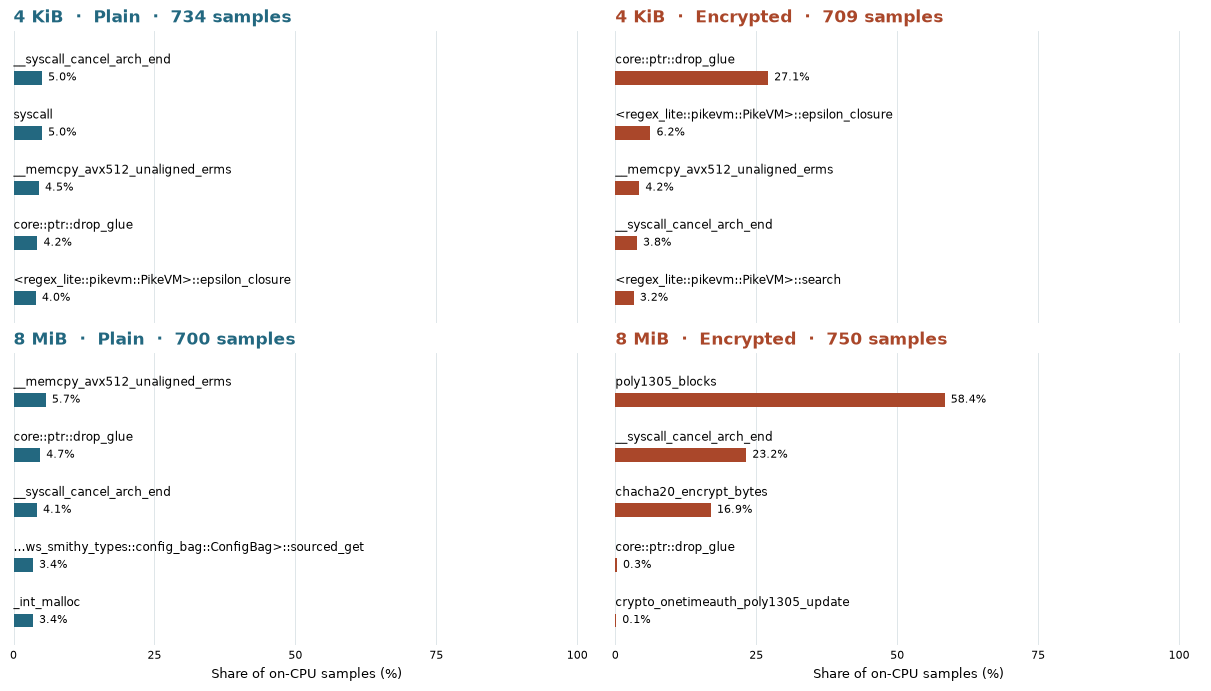

In [3]:
figure = cpu_hotspots(profiles)
display(figure)
plt.close(figure)

## Follow the sampled call stacks

Read from top to bottom. Each block starts at a sampled function and splits into the callers observed beneath it. Width is proportional to sample count. Change the payload or mode in the next cell to explore any of the four captures.

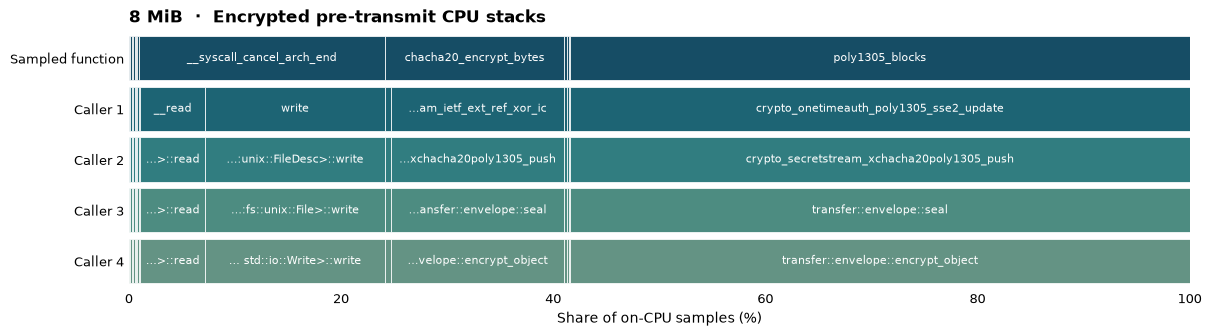

In [4]:
payload = "8mib"        # "4kib" or "8mib"
mode = "encrypted"      # "plain" or "encrypted"
label = {"4kib": "4 KiB", "8mib": "8 MiB"}[payload]
figure = cpu_callers(profiles[payload, mode], f"{label}  ·  {mode.capitalize()} pre-transmit CPU stacks")
display(figure)
plt.close(figure)

### Choose the runs

The recorded run is included. Set `run_fresh = True` and run all cells to compare this checkout with the recording. Cargo will compile the release benchmark if needed. The comparison uses one discarded warm-up per mode and 21 retained pairs per size, alternating which mode runs first.

In [5]:
run_fresh = False
if run_fresh:
    print("Measuring the release build from this source tree.")
    runs["Fresh"] = fresh_results(root)

## Plain and encrypted preparation

The 4 KiB panel uses microseconds and the 8 MiB panel uses milliseconds. When a fresh run is included, panels for the same size share an axis scale.

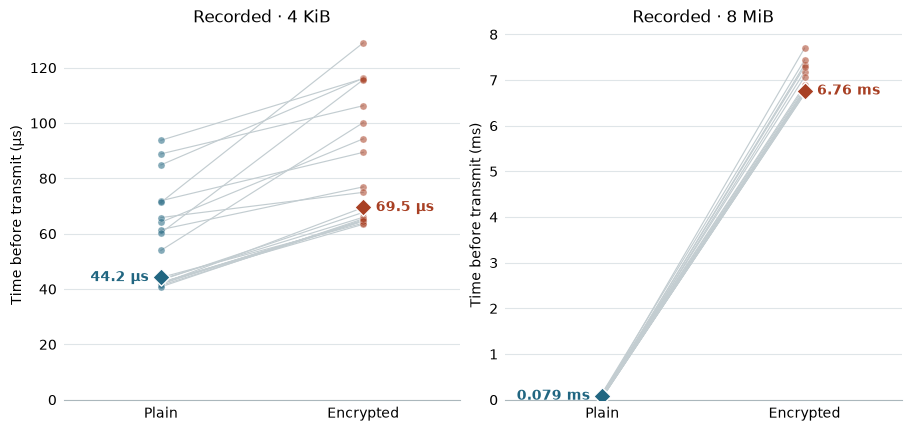

In [6]:
figure = paired_figure(runs)
display(figure)
plt.close(figure)

## Timing summary

The median difference subtracts the plain median from the encrypted median. The p95 column for each mode uses the nearest-rank rule.

In [7]:
lines = [
    "| Run | Payload | Plain median | Encrypted median | Median difference | Plain p95 | Encrypted p95 |",
    "|:----|:--------|------------:|-----------------:|------------------:|----------:|--------------:|",
]
for name, records in runs.items():
    for size, (label, unit, divisor) in WORKLOADS.items():
        row = records[size]
        plain, encrypted = row["plain_samples_ns"], row["samples_ns"]
        values = [median(plain), median(encrypted), median(encrypted) - median(plain),
                  nearest_rank_p95(plain), nearest_rank_p95(encrypted)]
        formatted = " | ".join(f"{value / divisor:,.3f} {unit}" for value in values)
        lines.append(f"| {name} | {label} | {formatted} |")
display(Markdown("\n".join(lines)))

| Run | Payload | Plain median | Encrypted median | Median difference | Plain p95 | Encrypted p95 |
|:----|:--------|------------:|-----------------:|------------------:|----------:|--------------:|
| Recorded | 4 KiB | 44.183 µs | 69.480 µs | 25.297 µs | 88.856 µs | 116.197 µs |
| Recorded | 8 MiB | 0.079 ms | 6.762 ms | 6.683 ms | 0.142 ms | 7.439 ms |

## Recorded conditions

In [8]:
print(f"{reference['observed_at']} · {reference['cpu']} · Rust {reference['rust']}")
print(f"{reference['os']} · {reference['filesystem']}")
print(f"{reference['host_load']}  Source commit {reference['commit'][:12]}.")

2026-11-25T02:02:46.783257+00:00 · AMD Ryzen AI Max+ 395 · Rust 1.97.1
Ubuntu 22.04 x86_64 userspace on Linux · Btrfs, warm source file and local anonymous ciphertext file
Shared host. A Nix build was active during the measurement.  Source commit 7a74b6b932f0.
